### Problem 16 : QAOA - quantum combinatorial optimization

Problem 15 used the hybrid loop to find the lowest energy of a *molecule*. The **Quantum
Approximate Optimization Algorithm** uses the very same machinery to solve a completely different
kind of problem : hard **combinatorial optimization**.

The trick that makes this possible is a change of clothes. Take any problem of the form "assign a
0 or a 1 to each of n objects so as to maximise some score". Encode each object as a qubit, write
the score as an energy, and suddenly *finding the best assignment* and *finding a ground state* are
the same task - and we already know how to do the second one.

This covers a huge amount of real work : portfolio selection, vehicle routing, scheduling, chip
layout, protein folding, and - directly relevant to this repo - **feature selection** and
**clustering** in machine learning.

**TASK :** Solve MaxCut on a small graph with QAOA, and watch the solution quality improve as we
add layers.

📄 Original paper : https://arxiv.org/abs/1411.4028

#### The problem : MaxCut

Given a graph, colour every vertex either black or white so as to **maximise the number of edges
whose two endpoints have different colours** (the "cut" edges).

It sounds like a puzzle; it is NP-hard. It is also the standard benchmark for QAOA, because it maps
onto qubits with essentially no effort :

- one qubit per vertex, ∣0⟩ = black, ∣1⟩ = white
- a bitstring like `1010` is a complete candidate solution
- the cut size of a bitstring is what we want to maximise

In [1]:
import pennylane as qml
from pennylane import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

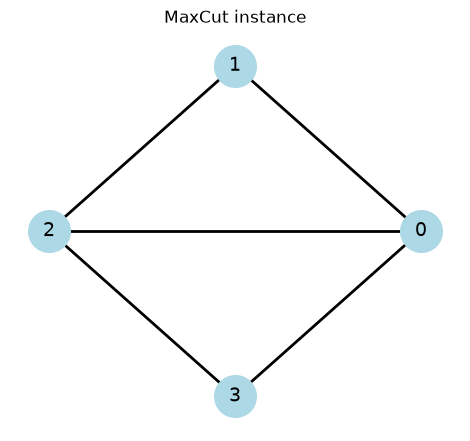

Vertices: 4  Edges: 5


In [2]:
# A small graph: a 4-cycle with one diagonal
edges = [(0, 1), (1, 2), (2, 3), (3, 0), (0, 2)]
graph = nx.Graph(edges)
n_wires = graph.number_of_nodes()

plt.figure(figsize=(4.5, 4))
nx.draw(graph, nx.circular_layout(graph), with_labels=True,
        node_color='lightblue', node_size=900, font_size=14, width=2)
plt.title("MaxCut instance"); plt.show()

print("Vertices:", n_wires, " Edges:", graph.number_of_edges())

In [3]:
# Brute force - with only 4 vertices we can check all 16 assignments and know the true answer
def cut_size(bitstring):
    return sum(1 for u, v in graph.edges if bitstring[u] != bitstring[v])


all_solutions = {}
for i in range(2 ** n_wires):
    b = format(i, f'0{n_wires}b')
    all_solutions[b] = cut_size(b)

optimal_cut = max(all_solutions.values())
optimal_strings = [b for b, c in all_solutions.items() if c == optimal_cut]

print("All assignments and their cut sizes:")
for b, c in sorted(all_solutions.items(), key=lambda kv: -kv[1]):
    print(f"  {b} -> {c}" + ("   <-- optimal" if c == optimal_cut else ""))
print(f"\nOptimal cut = {optimal_cut}, achieved by {optimal_strings}")

All assignments and their cut sizes:
  0101 -> 4   <-- optimal
  1010 -> 4   <-- optimal
  0010 -> 3
  0011 -> 3
  0110 -> 3
  0111 -> 3
  1000 -> 3
  1001 -> 3
  1100 -> 3
  1101 -> 3
  0001 -> 2
  0100 -> 2
  1011 -> 2
  1110 -> 2
  0000 -> 0
  1111 -> 0

Optimal cut = 4, achieved by ['0101', '1010']


#### From a graph to a Hamiltonian

Map each bit to a spin : zᵢ = +1 for ∣0⟩ and −1 for ∣1⟩. For a single edge (u, v),

**( 1 − z_u·z_v ) / 2**

equals 1 when the endpoints differ (the edge is cut) and 0 when they agree. Sum over all edges and
you have the cut size as a **sum of Z⊗Z terms** - an Ising Hamiltonian, exactly the kind of object
Problem 15 minimised.

By convention we write the *cost* Hamiltonian so that **lower energy = bigger cut**, so
⟨H_C⟩ = −(expected cut size). PennyLane's `qml.qaoa.maxcut` builds it for us, along with the
**mixer** Hamiltonian H_M = Σ Xᵢ.

#### The QAOA ansatz

QAOA alternates two operations, p times :

∣ψ(γ, β)⟩ = [ e^(−iβ_p H_M) e^(−iγ_p H_C) ] … [ e^(−iβ_1 H_M) e^(−iγ_1 H_C) ] ∣+⟩^⊗ⁿ

- Start in the **uniform superposition** ∣+⟩^⊗ⁿ - every possible assignment at once, equally likely.
- The **cost layer** e^(−iγH_C) stamps a phase on each assignment proportional to how good it is.
- The **mixer layer** e^(−iβH_M) lets amplitude flow between assignments, converting those phases
  into differences in probability.

Repeat, and amplitude piles up on good solutions. Just **2p parameters**, regardless of how big the
graph is - and, like VQE, the ansatz is derived from the problem rather than guessed, so barren
plateaus are far less of an issue.

> This is a discretised version of **adiabatic quantum computing** : as p → ∞, QAOA can reproduce a
> slow interpolation from the mixer's ground state to the cost Hamiltonian's ground state, and is
> then guaranteed to find the optimum.

In [4]:
cost_h, mixer_h = qml.qaoa.maxcut(graph)

print("Cost Hamiltonian:")
print(cost_h)
print()
print("Mixer Hamiltonian:")
print(mixer_h)

Cost Hamiltonian:
0.5 * (Z(0) @ Z(1)) + 0.5 * (Z(0) @ Z(3)) + 0.5 * (Z(0) @ Z(2)) + 0.5 * (Z(1) @ Z(2)) + 0.5 * (Z(2) @ Z(3)) + -0.5 * (I(0) @ I(1)) + -0.5 * (I(0) @ I(3)) + -0.5 * (I(0) @ I(2)) + -0.5 * (I(1) @ I(2)) + -0.5 * (I(2) @ I(3))

Mixer Hamiltonian:
1 * X(0) + 1 * X(1) + 1 * X(2) + 1 * X(3)


In [5]:
dev = qml.device("default.qubit", wires=n_wires)


def qaoa_layer(gamma, beta):
    qml.qaoa.cost_layer(gamma, cost_h)      # exp(-i gamma H_C)
    qml.qaoa.mixer_layer(beta, mixer_h)     # exp(-i beta  H_M)


def build_qaoa(p):
    """Return (expectation-value qnode, probability qnode) for depth p."""

    def prepare(params):
        for w in range(n_wires):
            qml.Hadamard(w)                 # the uniform superposition |+>^n
        qml.layer(qaoa_layer, p, params[0], params[1])

    @qml.qnode(dev)
    def expectation(params):
        prepare(params)
        return qml.expval(cost_h)

    @qml.qnode(dev)
    def distribution(params):
        prepare(params)
        return qml.probs(wires=range(n_wires))

    return expectation, distribution

In [6]:
# Step 1: Train a depth-2 QAOA
p = 2
expectation, distribution = build_qaoa(p)

np.random.seed(0)
params = np.array([np.random.uniform(0, 1, p),      # the gammas
                   np.random.uniform(0, 1, p)],     # the betas
                  requires_grad=True)

opt = qml.AdamOptimizer(stepsize=0.1)

print(f"Initial expected cut: {-float(expectation(params)):.4f}")
for step in range(150):
    params = opt.step(expectation, params)
    if (step + 1) % 30 == 0:
        print(f"Step {step + 1:3d} | expected cut {-float(expectation(params)):.4f}")

print()
print("gammas:", np.round(params[0], 4))
print("betas :", np.round(params[1], 4))

Initial expected cut: 0.8391
Step  30 | expected cut 3.3751
Step  60 | expected cut 3.4505
Step  90 | expected cut 3.4569
Step 120 | expected cut 3.4573
Step 150 | expected cut 3.4573

gammas: [0.5171 1.1201]
betas : [1.1794 1.3707]


In [7]:
# Step 2: Read out the answer - sample the final state
probs = distribution(params)
basis = [format(i, f'0{n_wires}b') for i in range(2 ** n_wires)]

print("Most likely bitstrings:")
for i in np.argsort(probs)[::-1][:6]:
    b = basis[int(i)]
    star = "  <-- OPTIMAL" if cut_size(b) == optimal_cut else ""
    print(f"  {b}  probability {float(probs[int(i)]):.4f}  cut {cut_size(b)}{star}")

p_optimal = float(sum(probs[i] for i, b in enumerate(basis) if cut_size(b) == optimal_cut))
print(f"\nTotal probability of measuring an optimal solution: {p_optimal:.3f}")
print(f"(random guessing would give {len(optimal_strings) / 2 ** n_wires:.3f})")

Most likely bitstrings:
  1010  probability 0.2371  cut 4  <-- OPTIMAL
  0101  probability 0.2371  cut 4  <-- OPTIMAL
  1100  probability 0.0718  cut 3
  0011  probability 0.0718  cut 3
  1001  probability 0.0718  cut 3
  0110  probability 0.0718  cut 3

Total probability of measuring an optimal solution: 0.474
(random guessing would give 0.125)


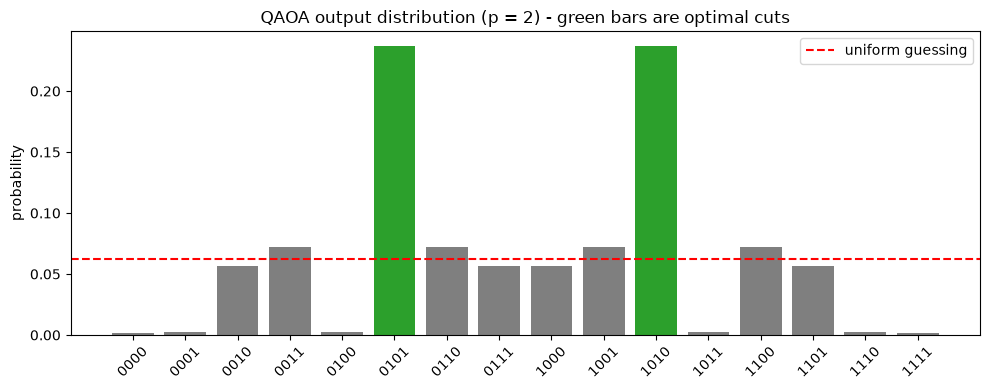

In [8]:
plt.figure(figsize=(10, 4))
colors = ['tab:green' if cut_size(b) == optimal_cut else 'tab:gray' for b in basis]
plt.bar(basis, probs, color=colors)
plt.axhline(1 / 2 ** n_wires, color='r', linestyle='--', label='uniform guessing')
plt.xticks(rotation=45); plt.ylabel("probability")
plt.title(f"QAOA output distribution (p = {p}) - green bars are optimal cuts")
plt.legend(); plt.tight_layout(); plt.show()

#### Step 3 : Does depth help ?

The theory says the approximation ratio improves monotonically with p, and that as p → ∞ QAOA
becomes exact. Let us check on our graph.

The metric is the **approximation ratio** :

**ratio = ⟨cut⟩ / optimal cut**

A value of 1.0 means we always output an optimal solution.

In [9]:
results = []

for p_test in [1, 2, 3, 4]:
    exp_fn, dist_fn = build_qaoa(p_test)

    np.random.seed(0)
    par = np.array([np.random.uniform(0, 1, p_test),
                    np.random.uniform(0, 1, p_test)], requires_grad=True)

    o = qml.AdamOptimizer(stepsize=0.1)
    for _ in range(150):
        par = o.step(exp_fn, par)

    pr = dist_fn(par)
    expected_cut = -float(exp_fn(par))
    p_opt = float(sum(pr[i] for i, b in enumerate(basis) if cut_size(b) == optimal_cut))

    results.append((p_test, expected_cut, expected_cut / optimal_cut, p_opt))
    print(f"p = {p_test} | expected cut {expected_cut:.3f} | "
          f"approximation ratio {expected_cut / optimal_cut:.3f} | P(optimal) {p_opt:.3f}")

p = 1 | expected cut 3.237 | approximation ratio 0.809 | P(optimal) 0.328


p = 2 | expected cut 3.457 | approximation ratio 0.864 | P(optimal) 0.474


p = 3 | expected cut 3.579 | approximation ratio 0.895 | P(optimal) 0.602
p = 4 | expected cut 3.987 | approximation ratio 0.997 | P(optimal) 0.989


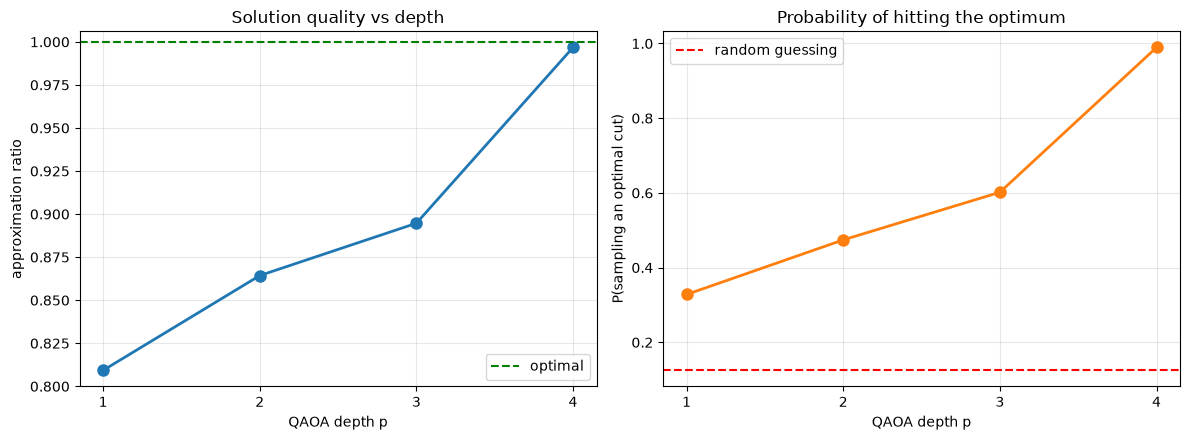

In [10]:
ps = [r[0] for r in results]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.plot(ps, [r[2] for r in results], 'o-', linewidth=2, markersize=8)
ax1.axhline(1.0, color='g', linestyle='--', label='optimal')
ax1.set_xlabel("QAOA depth p"); ax1.set_ylabel("approximation ratio")
ax1.set_title("Solution quality vs depth"); ax1.set_xticks(ps)
ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(ps, [r[3] for r in results], 'o-', color='tab:orange', linewidth=2, markersize=8)
ax2.axhline(len(optimal_strings) / 2 ** n_wires, color='r', linestyle='--', label='random guessing')
ax2.set_xlabel("QAOA depth p"); ax2.set_ylabel("P(sampling an optimal cut)")
ax2.set_title("Probability of hitting the optimum"); ax2.set_xticks(ps)
ax2.legend(); ax2.grid(alpha=0.3)

plt.tight_layout(); plt.show()

#### OUTCOME :

The approximation ratio climbs steadily with depth and the probability of sampling an optimal cut
goes from around 30% at p = 1 to nearly certain at p = 4 - against 12.5% for random guessing. With
just **8 parameters** we solved the problem.

#### Honesty check

QAOA is a genuinely elegant algorithm and there is still **no proof** that it beats the best
classical heuristics on any practical problem. For MaxCut specifically, the classical
Goemans-Williamson algorithm guarantees a 0.878 approximation ratio in polynomial time, and low-depth
QAOA struggles to beat it. The open questions are exactly the ones this repo keeps running into :

- **Depth costs noise.** Each extra layer means more two-qubit gates - see Problem 14.
- **The parameter landscape is hard.** Non-convex, with many local optima, though good heuristics
  exist for initialising the angles.
- **Sampling costs shots.** You need enough shots to actually find the good bitstring in the
  distribution.

Treat QAOA as a promising and beautifully structured *candidate*, not a solved advantage.

#### Where this touches Quantum AI

- **Feature selection** is MaxCut's cousin : choose the subset of features maximising relevance
  while minimising redundancy - a quadratic binary optimization, i.e. an Ising model.
- **Clustering** can be written as graph partitioning, which is MaxCut.
- **Training binary/discrete networks** is combinatorial optimization.
- The QAOA ansatz is regularly reused as a *machine learning* ansatz, because unlike the generic
  entanglers of Problem 12 it carries structure and resists barren plateaus.

#### Key Takeaways :
- Any "choose 0 or 1 for each object" problem becomes an Ising Hamiltonian, hence a ground-state problem.
- QAOA alternates a **cost** layer (phases in the good solutions) and a **mixer** layer (turns phases into probabilities).
- Only **2p parameters**, independent of problem size.
- Quality improves with depth, but so does the noise - and no practical quantum advantage is proven yet.

#### TASK :
1. Run the same code on a larger random graph, e.g. `nx.erdos_renyi_graph(8, 0.5, seed=42)`.
   Does p = 2 still get close to the optimum? Brute force is still feasible at 8 nodes - check.
2. Try a graph that is **bipartite**, like `nx.complete_bipartite_graph(2, 3)`, where every edge can
   be cut at once. Does QAOA find the perfect cut more easily?
3. Replace the X mixer with `qml.qaoa.xy_mixer`. This mixer conserves the number of 1s - useful when
   you need exactly k objects chosen. Which problems does that unlock?
4. Add the noise model from Problem 14 and re-run the depth sweep. Find the depth at which noise
   starts to *hurt* more than the extra layer helps.